# 01 · Your first light curve

**Level:** beginner · **Prerequisites:** basic Python and NumPy · **Run time:** ~20 s

**Covers:** `TransitParams`, `TransitModel`, `light_curve`, units, the effect of each parameter, the six limb-darkening laws

We build the light curve of a hot Jupiter step by step and see what each parameter does to its shape.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pizzetti

print("pizzetti", pizzetti.__version__)

pizzetti 0.3.0


## 1. Describe the system: `TransitParams`

All lengths are in units of the stellar radius, angles in degrees, and times in whatever unit you
use for `t` (days here).

| attribute | meaning |
|---|---|
| `t0` | time of mid-transit (inferior conjunction) |
| `per` | orbital period |
| `rp` | planet radius / stellar radius |
| `a` | semi-major axis / stellar radius |
| `inc` | orbital inclination (90° = central transit) |
| `ecc`, `w` | eccentricity and argument of periastron |
| `limb_dark`, `u` | limb-darkening law and its coefficients |

In [2]:
params = pizzetti.TransitParams()
params.t0 = 0.0
params.per = 3.5
params.rp = 0.1          # a Jupiter around a Sun-like star
params.a = 9.0
params.inc = 87.0
params.ecc = 0.0
params.w = 90.0
params.limb_dark = "quadratic"
params.u = [0.4, 0.25]

b = params.a * np.cos(np.radians(params.inc))
print(f"impact parameter b = a cos(inc) = {b:.2f}")

impact parameter b = a cos(inc) = 0.47


## 2. Compute the light curve: `TransitModel`

`TransitModel(params, t)` stores the times and computes the planet-star separations; `light_curve(params)`
returns the relative flux (1 out of transit). The first call compiles the numerical kernels (a few seconds,
then cached on disk); afterwards a call takes microseconds.

depth at mid-transit: 11487 ppm


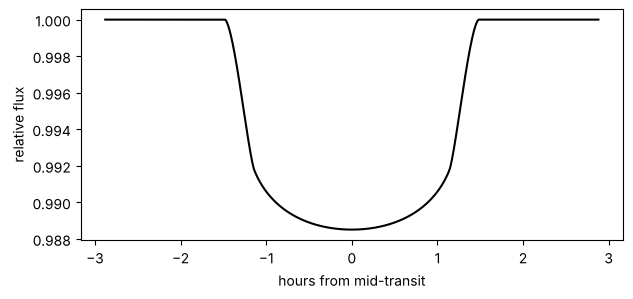

In [3]:
t = np.linspace(-0.12, 0.12, 2000)             # days around mid-transit
model = pizzetti.TransitModel(params, t)
flux = model.light_curve(params)

plt.figure(figsize=(7, 3))
plt.plot(24 * t, flux, "k")
plt.xlabel("hours from mid-transit"); plt.ylabel("relative flux")
print(f"depth at mid-transit: {1e6 * (1 - flux.min()):.0f} ppm")

The depth is close to `rp²` = 1 % but not equal to it: the star is darker towards its edge
(*limb darkening*), so the planet blocks more than the average brightness when it crosses the centre.

## 3. What each parameter does

Change an attribute and call `light_curve` again with the same model; there is no need to build a
new `TransitModel` unless the times change.

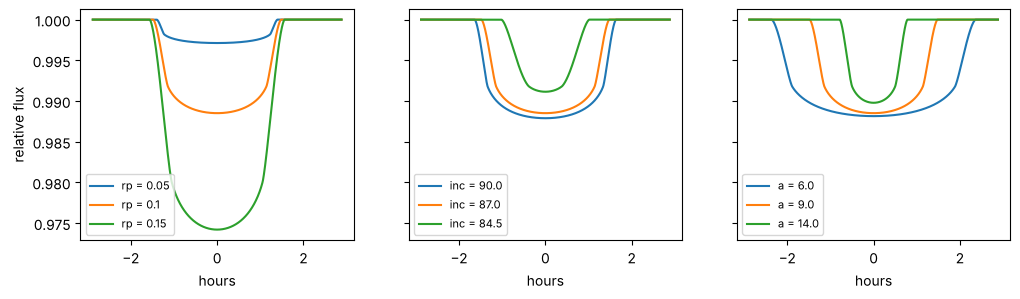

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, (name, values) in zip(axes, [("rp", [0.05, 0.1, 0.15]), ("inc", [90.0, 87.0, 84.5]), ("a", [6.0, 9.0, 14.0])]):
    old = getattr(params, name)
    for v in values:
        setattr(params, name, v)
        ax.plot(24 * t, model.light_curve(params), label=f"{name} = {v}")
    setattr(params, name, old)
    ax.legend(fontsize=8); ax.set_xlabel("hours")
axes[0].set_ylabel("relative flux");

- **`rp`** sets the depth (∝ rp²).
- **`inc`** (through b = a cos inc) moves the chord away from the centre: shallower, shorter, more V-shaped.
  At b > 1 + rp there is no transit.
- **`a`** sets the duration (the planet moves faster on a tighter orbit).

## 4. Limb-darkening laws

The intensity across the stellar disk is a function of μ, the cosine of the angle between the line of
sight and the surface normal (μ = 1 at the centre, 0 at the limb). pizzetti supports every law of batman
that is a sum of powers of μ:

| `limb_dark` | I(μ) / I(1) | coefficients `u` |
|---|---|---|
| `uniform` | 1 | — |
| `linear` | 1 − u₁(1 − μ) | u₁ |
| `quadratic` | 1 − u₁(1 − μ) − u₂(1 − μ)² | u₁, u₂ |
| `squareroot` | 1 − u₁(1 − μ) − u₂(1 − √μ) | u₁, u₂ |
| `nonlinear` | 1 − Σₙ cₙ(1 − μ^{n/2}) | c₁ … c₄ |
| `power2` | 1 − c(1 − μ^α) | c, α |

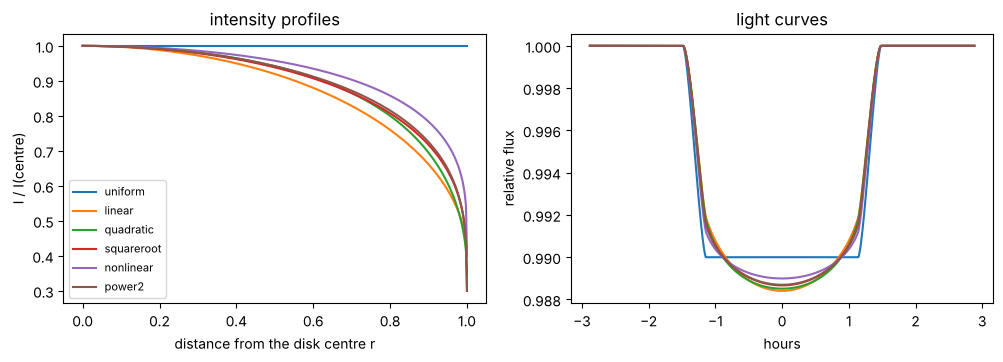

In [5]:
laws = {"uniform": [], "linear": [0.6], "quadratic": [0.4, 0.25], "squareroot": [0.2, 0.5],
        "nonlinear": [0.5, 0.1, 0.1, -0.1], "power2": [0.7, 0.6]}

def intensity(law, u, mu):
    if law == "uniform":    return np.ones_like(mu)
    if law == "linear":     return 1 - u[0] * (1 - mu)
    if law == "quadratic":  return 1 - u[0] * (1 - mu) - u[1] * (1 - mu)**2
    if law == "squareroot": return 1 - u[0] * (1 - mu) - u[1] * (1 - np.sqrt(mu))
    if law == "nonlinear":  return 1 - sum(c * (1 - mu**(n / 2)) for n, c in enumerate(u, 1))
    if law == "power2":     return 1 - u[0] * (1 - mu**u[1])

r = np.linspace(0, 1, 400)
mu = np.sqrt(1 - r**2)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.5))
for law, u in laws.items():
    params.limb_dark, params.u = law, u
    a1.plot(r, intensity(law, u, mu), label=law)
    a2.plot(24 * t, model.light_curve(params), label=law)
params.limb_dark, params.u = "quadratic", [0.4, 0.25]
a1.set(xlabel="distance from the disk centre r", ylabel="I / I(centre)", title="intensity profiles")
a2.set(xlabel="hours", ylabel="relative flux", title="light curves")
a1.legend(fontsize=8);

Limb darkening rounds the bottom of the transit; the uniform disk gives a flat bottom. Which law to use
for real data is the topic of [notebook 05](05_choosing_a_limb_darkening_law.ipynb).

## 5. Several transits

`t` can be any array of times, for example several transits observed at a fixed cadence. Folding on
the period puts them on top of each other.

940 samples


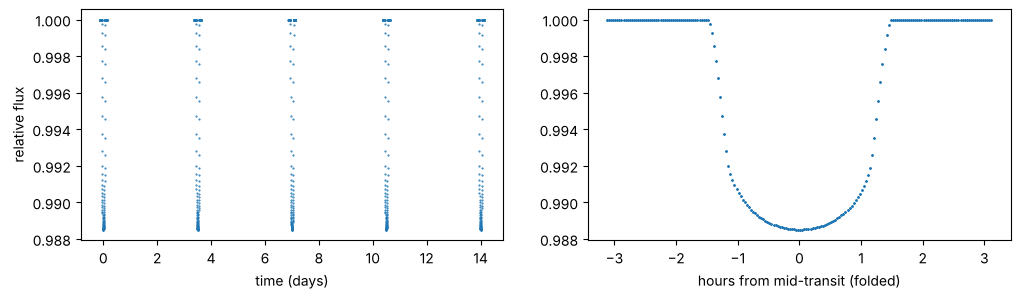

In [6]:
cadence = 2.0 / 1440                                  # 2 minutes, in days
t_multi = np.concatenate([np.arange(e * params.per - 0.13, e * params.per + 0.13, cadence) for e in range(5)])
m_multi = pizzetti.TransitModel(params, t_multi)
f_multi = m_multi.light_curve(params)
fold = (t_multi - params.t0 + 0.5 * params.per) % params.per - 0.5 * params.per
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3))
a1.plot(t_multi, f_multi, ".", ms=1); a1.set(xlabel="time (days)", ylabel="relative flux")
a2.plot(24 * fold, f_multi, ".", ms=1); a2.set(xlabel="hours from mid-transit (folded)")
print(len(t_multi), "samples")

## What you learned

- `TransitParams` holds the system; `TransitModel(params, t)` fixes the times; `light_curve(params)` computes the flux.
- Reuse one model while parameters change; build a new one only for new times.
- `rp` sets the depth, `inc` (impact parameter) the shape, `a` the duration; limb darkening rounds the bottom.
- Six limb-darkening laws are available, all sums of powers of μ.

**Next:** [02 · Coming from batman](02_coming_from_batman.ipynb)